In [1]:
import numpy as np

In [2]:
pip install -r requirements.txt

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


# Task 1: Vanilla Convolution Implementation (Output Side Algorithm)

In [3]:
def convolution_1d_outputside(data: np.ndarray, kernel: np.ndarray, mode: str = 'same') -> np.ndarray:
    """
    Perform 1D discrete convolution manually.

    Parameters
    ----------
    data : np.ndarray
        Input signal array

    kernel : np.ndarray
        Convolution kernel array

    mode : str, optional
        Mode of convolution ('same' or 'full'), by default 'same'

    Returns
    -------
    np.ndarray
        Convolved output
    """

    ## Your Task should be coded here

    N = len(data)
    M = len(kernel)

    full_len = N + M - 1

    output_full = np.zeros(full_len)

    for n in range(full_len):
        s = 0

        for k in range(M):
            x_index = n - k

            if 0 <= x_index < N:
                s += data[x_index] * kernel[k]

        output_full[n] = s

    if mode == 'full':
        return output_full

    elif mode == 'same':
        start = (M - 1) // 2
        return output_full[start:start + N]

    else:
        raise ValueError("mode must be 'same' or 'full'")



    output = None
    return output

## Result Verification

In [4]:
# Example input
data = np.array([1, 2, 3, 4, 5])
kernel = np.array([1, 0, -1])


mode = 'same'
result = convolution_1d_outputside(data, kernel, mode=mode)
result_np = np.convolve(data, kernel, mode=mode)

print("Same Convolution Output:")
print(result)
print("Same NumPy Convolution Output:")
print(result_np)


mode = 'full'
result = convolution_1d_outputside(data, kernel, mode=mode)
result_np = np.convolve(data, kernel, mode=mode)

print("Full Convolution Output:")
print(result)
print("Full NumPy Convolution Output:")
print(result_np)

Same Convolution Output:
[ 2.  2.  2.  2. -4.]
Same NumPy Convolution Output:
[ 2  2  2  2 -4]
Full Convolution Output:
[ 1.  2.  2.  2.  2. -4. -5.]
Full NumPy Convolution Output:
[ 1  2  2  2  2 -4 -5]


# Task 2: Vanilla Convolution Implementation (Input Side Algorithm)

In [ ]:
def convolution_1d_inputside(data: np.ndarray, kernel: np.ndarray, mode: str = 'same') -> np.ndarray:
    """
    Perform 1D discrete convolution manually.

    Parameters
    ----------
    data : np.ndarray
        Input signal array

    kernel : np.ndarray
        Convolution kernel array

    mode : str, optional
        Mode of convolution ('same' or 'full'), by default 'same'

    Returns
    -------
    np.ndarray
        Convolved output
    """

    ## Your Task should be coded here
    N = len(data)
    M = len(kernel)

    full_len = N + M - 1

    output_full = np.zeros(full_len)

    for n in range(N):
        for m in range(M):
            output_full[n + m] += data[n] * kernel[m]

    if mode == 'full':
        return output_full

    elif mode == 'same':
        start = (M - 1) // 2
        return output_full[start:start + N]

    else:
        raise ValueError("mode must be 'same' or 'full'")

    output = None
    return output

## Result Verification

In [ ]:
# Example input
data = np.array([1, 2, 3, 4, 5])
kernel = np.array([1, 0, -1])


mode = 'same'
result = convolution_1d_inputside(data, kernel, mode=mode)
result_np = np.convolve(data, kernel, mode=mode)

print("Same Convolution Output:")
print(result)
print("Same NumPy Convolution Output:")
print(result_np)


mode = 'full'
result = convolution_1d_inputside(data, kernel, mode=mode)
result_np = np.convolve(data, kernel, mode=mode)

print("Full Convolution Output:")
print(result)
print("Full NumPy Convolution Output:")
print(result_np)

Same Convolution Output:
None
Same NumPy Convolution Output:
[ 2  2  2  2 -4]
Full Convolution Output:
None
Full NumPy Convolution Output:
[ 1  2  2  2  2 -4 -5]


# Task 3: Row-wise Image Convolution with Custom Kernels

A black-and-white image is provided as a 2D NumPy array. A helper function applies **1D convolution independently to each row** of the image. Each row is convolved in `mode='full'` and the result is truncated to the original row length, so samples outside the left boundary are treated as zero.

Your task is to design convolution kernels that produce specific row-wise effects when passed to this function.

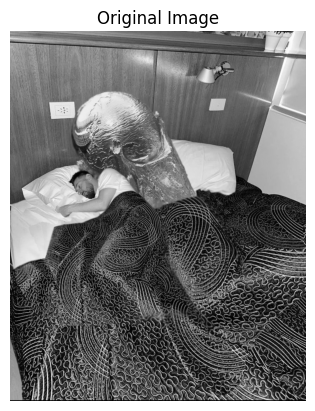

Image shape: (800, 640)


In [5]:
import matplotlib.pyplot as plt
from PIL import Image


def convolution_2d_rowwise(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """
    Apply 1D convolution independently to each row of a 2D grayscale image.

    Parameters
    ----------
    image : np.ndarray
        2D grayscale image array (rows x columns)

    kernel : np.ndarray
        1D convolution kernel

    Returns
    -------
    np.ndarray
        Filtered image with the same shape as the input
    """
    image = image.astype(np.float64)
    output = np.zeros_like(image)

    width = image.shape[1]

    for row in range(image.shape[0]):
        output[row] = np.convolve(image[row], kernel, mode='full')[:width]

    return output


# Load the provided black-and-white image
image_path = "image.jpg"
image = np.array(Image.open(image_path).convert("L"), dtype=np.float64)

plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")
plt.show()

print(f"Image shape: {image.shape}")

## Subtask 1: Row-wise Moving Average Kernel

Design a 1D kernel that, when applied row-wise, replaces each pixel with the **average of `n` adjacent pixels in the same row** (including the current pixel and the `n - 1` pixels to its left). Choose a value for `n` and implement the kernel below.

In [8]:
def averaging_kernel(n: int) -> np.ndarray:
    """
    Return a 1D kernel that averages n adjacent pixels in a row.

    Parameters
    ----------
    n : int
        Number of adjacent pixels to average (kernel length)

    Returns
    -------
    np.ndarray
        1D averaging kernel
    """

    ## Your Task should be coded here
    kernel = np.ones(n)

    kernel = kernel / n

    return kernel

### Result Verification (Subtask 1)

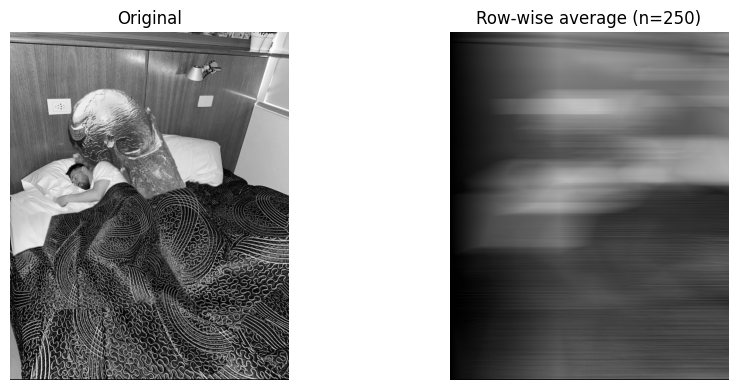

Averaging kernel:
[0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004 0.004
 0.004 0.004 0.004 0.004 0.004 0.

In [19]:
n = 250  # change this to test different window sizes

avg_kernel = averaging_kernel(n)
averaged_image = convolution_2d_rowwise(image, avg_kernel)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(averaged_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Row-wise average (n={n})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Averaging kernel:")
print(avg_kernel)

## Subtask 2: Row-wise Shift Kernel

Design a 1D kernel that, when applied row-wise, **shifts each row `n` units to the right**. Pixels that move past the right boundary are discarded; vacated positions on the left are filled with zero.

In [12]:
def shift_kernel(n: int) -> np.ndarray:
    """
    Return a 1D kernel that shifts a row n units to the right.

    Parameters
    ----------
    n : int
        Number of positions to shift each row to the right

    Returns
    -------
    np.ndarray
        1D shift kernel
    """

    ## Your Task should be coded here
    kernel = np.zeros(n + 1)

    kernel[n] = 1

    return kernel

### Result Verification (Subtask 2)

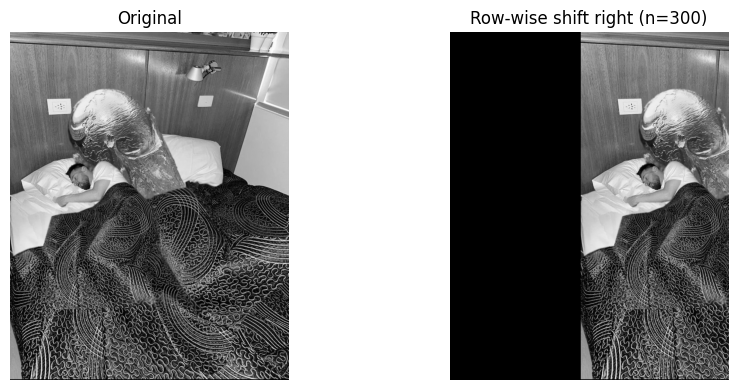

Shift kernel:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


In [16]:
n = 300  # change this to test different shift amounts

shift_k = shift_kernel(n)
shifted_image = convolution_2d_rowwise(image, shift_k)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(shifted_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Row-wise shift right (n={n})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Shift kernel:")
print(shift_k)